# Principal Component Analysis (PCA)

Explained variance ratio per component:
[0.2737 0.1337 0.128  0.1263 0.1241 0.1172 0.0898 0.0071]
Cumulative explained variance:
[0.2737 0.4075 0.5354 0.6618 0.7859 0.903  0.9929 1.    ]


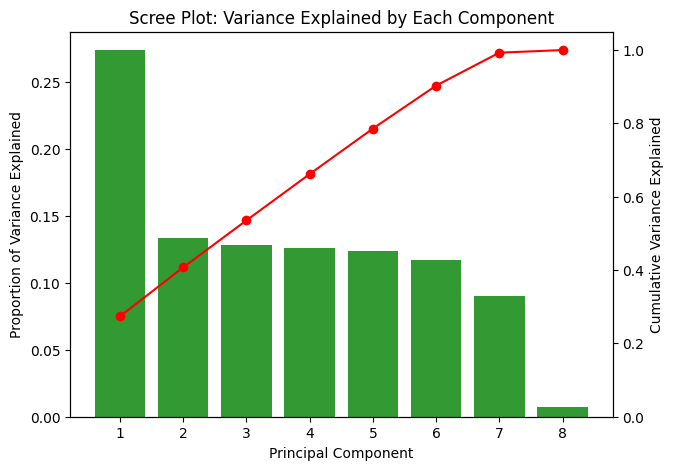

[[ 0.64097819  0.64044058  0.04521273  0.02975829 -0.0971871   0.01388179
   0.01205031  0.40776197]
 [ 0.08677892  0.00441955 -0.49490755  0.58008743 -0.57455025 -0.04811646
   0.08063107 -0.2684966 ]]
Total variance retained by 2 PC Components: [0.274 0.134]


/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sharonbayela/Documents/Machine Learning for Data Science/My project/project/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


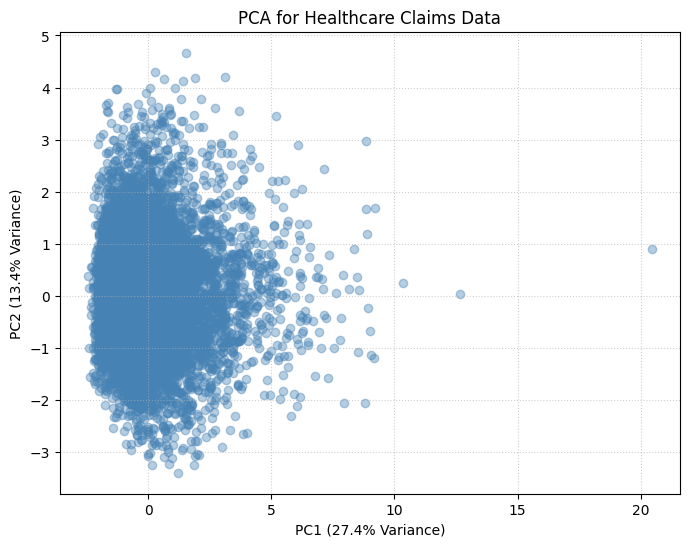


Component loadings:
                         PC1    PC2
Claim_Amount           0.641  0.087
Approved_Amount        0.640  0.004
Patient_Age            0.045 -0.495
No_of_Claims_Provider  0.030  0.580
Service_Claim_days    -0.097 -0.575
Length_of_Stay         0.014 -0.048
Prior_Visits_12m       0.012  0.081
Premiums               0.408 -0.268


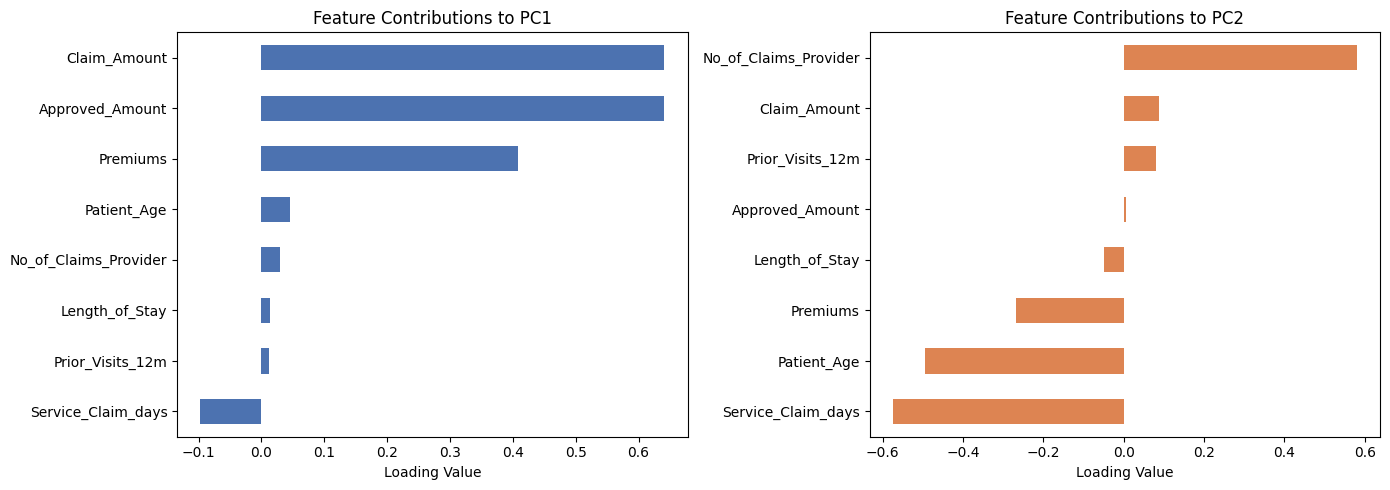

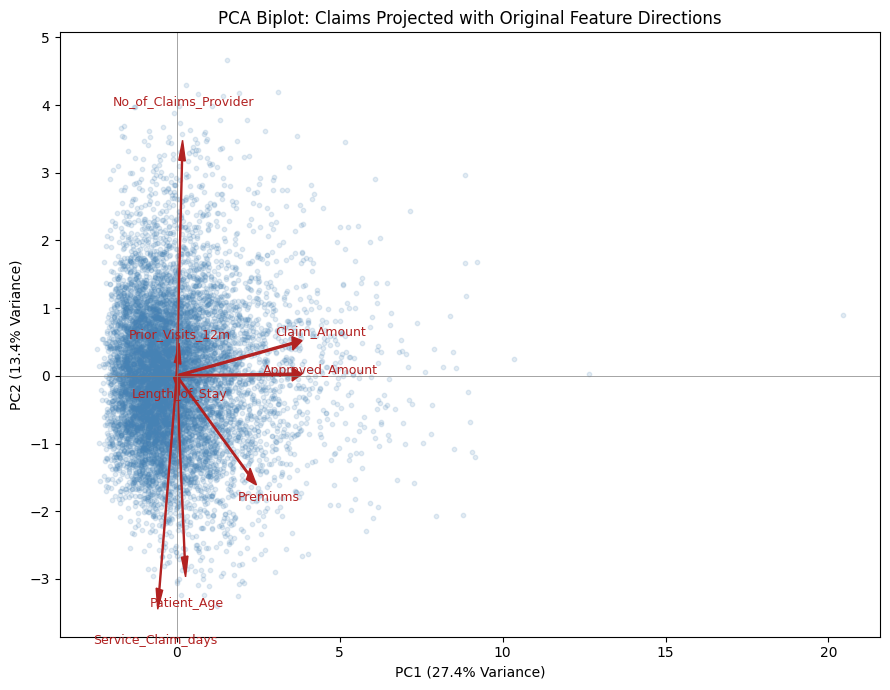

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt


health_data = pd.read_csv('health_data.csv')

num_cols = ['Claim_Amount','Approved_Amount', 'Patient_Age', 'No_of_Claims_Provider',
                       'Service_Claim_days','Length_of_Stay','Prior_Visits_12m', 'Premiums']


pca_data = health_data[num_cols].dropna()
feature_names = pca_data.columns.tolist()

# Standardizing the data before applying PCA
scaler = StandardScaler()
scaled_data = scaler.fit_transform(pca_data)

# Fitting PCA using all components first
pca_full = PCA()
pca_full.fit(scaled_data)

print("Explained variance ratio per component:")
print(np.round(pca_full.explained_variance_ratio_, 4))

print("Cumulative explained variance:")
print(np.round(np.cumsum(pca_full.explained_variance_ratio_), 4))

# Scree plot and Cumulative plot: variance explained by each component
components = np.arange(1, len(pca_full.explained_variance_ratio_) + 1)

fig, ax1 = plt.subplots(figsize=(7, 5))
ax1.bar(components, pca_full.explained_variance_ratio_, color='green', alpha=0.8, label='Individual')
ax1.set_xlabel('Principal Component')
ax1.set_ylabel('Proportion of Variance Explained')
ax1.set_title('Scree Plot: Variance Explained by Each Component')

ax2 = ax1.twinx()
ax2.plot(components, np.cumsum(pca_full.explained_variance_ratio_), color='red', marker='o', label='Cumulative')
ax2.set_ylabel('Cumulative Variance Explained')
ax2.set_ylim(0, 1.05)

plt.savefig('pca_scree_plot.png', dpi=300, bbox_inches='tight')
plt.show()

# Viewing PC1 and PC2
pca = PCA(n_components=2)
z = pca.fit_transform(scaled_data)

print(pca.components_)
print(f"Total variance retained by 2 PC Components:", pca.explained_variance_ratio_.round(3))

pca_data = pd.DataFrame(z, columns=['PC1', 'PC2'])

plt.figure(figsize=(8,6))
plt.scatter(pca_data['PC1'], pca_data['PC2'], color='steelblue', alpha=0.4)
plt.title('PCA for Healthcare Claims Data')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# ------------------------------------------------------------------
# LOADINGS: WHICH ORIGINAL FEATURES DRIVE PC1 AND PC2
# ------------------------------------------------------------------
loadings = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2'], index= feature_names)
print("\nComponent loadings:")
print(loadings.round(3))

# Bar charts of each feature's contribution to PC1 and PC2
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

loadings['PC1'].sort_values().plot(kind='barh', ax=axes[0], color='#4C72B0')
axes[0].set_title('Feature Contributions to PC1')
axes[0].set_xlabel('Loading Value')

loadings['PC2'].sort_values().plot(kind='barh', ax=axes[1], color='#DD8452')
axes[1].set_title('Feature Contributions to PC2')
axes[1].set_xlabel('Loading Value')

plt.tight_layout()
plt.savefig('pca_loadings_barchart.png', dpi=300, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------
# BIPLOT: DATA POINTS + ORIGINAL FEATURE DIRECTIONS OVERLAID
# ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(z[:, 0], z[:, 1], alpha=0.15, s=10, color='steelblue')

scale_factor = 6
for i, feature in enumerate(feature_names):
    pc1_val = loadings['PC1'].iloc[i]
    pc2_val = loadings['PC2'].iloc[i]
    ax.arrow(0, 0, pc1_val * scale_factor, pc2_val * scale_factor,
              color='firebrick', width=0.03, head_width=0.2, length_includes_head=True)
    ax.text(pc1_val * scale_factor * 1.15, pc2_val * scale_factor * 1.15,
             feature, color='firebrick', fontsize=9, ha='center')

ax.set_title('PCA Biplot: Claims Projected with Original Feature Directions')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)')
ax.axhline(0, color='gray', linewidth=0.5)
ax.axvline(0, color='gray', linewidth=0.5)

plt.tight_layout()
plt.savefig('pca_biplot.png', dpi=300, bbox_inches='tight')
plt.show()


pca_data.to_csv('pca_results.csv', index=False)